In [525]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
import scipy.special as sp
plt.rcParams['figure.figsize'] = (10,10)
from multiprocess import Pool
import os
os.environ["OMP_NUM_THREADS"] = "1"
import batoid
import poppy

In [526]:
def telescopeCreation(WL, dxs=0, dys=0, dzs=0, txs=0, tys=0):

    K=1000 #meter conversion
    #global WL
    global telescope, M1

    global outter1, inner1, outterD

        ### Primary ###
    R1, conic1, inner1, outter1 = -3500/K, -0.982, 115/K, 400/K
    M1coord = defineCoordinate().local()
    M1 = optic('M1', type='Quadric', RoC=R1, conic=conic1, inDiam=inner1, outDiam=outter1, coordSys=M1coord).mirror()
        ###############

        ### Seconday ###
    R2, conic2, outter2 = -855.28/K, -1.93, 88.063510/K
    pos2 = -1400/K
    M2coord = defineCoordinate(posX=dxs, posY=dys, posZ=pos2+dzs/K, anglX=txs, anglY=tys).local()
    M2 = optic('M2', type='Quadric', RoC=R2, conic=conic2, outDiam=outter2, coordSys=M2coord).mirror()
        ################

        ### Tertiary ###
    R3, conic3, outter3 = -1131.9/K, -0.6077, 113.181806/K
    pos3 = 1400.18/K
    M3coord = defineCoordinate(posZ=pos3).local()
    M3 = optic('M3', type='Quadric', RoC=R3, conic=conic3, outDiam=outter3, coordSys=M3coord).mirror()
        ################

        ### Detector ###
    outterD = 102.58/K
    posD = -211/K
    Dcoord = defineCoordinate(posZ=posD).local()
    D = optic('D', outDiam=outterD, coordSys=Dcoord).detector()
        ################

        ### HST ###
    telescope = build.compoundOptic(M1, M2, M3, D,
                                   pupilSize=outter1, backDist=1500/K,
                                   EPcoord=defineCoordinate(posZ=0).local())
    
    return telescope

In [527]:
def showLayout(show='2D'):
    start = time.time()

    ## Field bias + Number of rays per field`
    nbOfRaysPerField = 6 # should be even

    ## Rays of central field
    anglX, anglY = 0, 0
    anglY += fieldBias
    field0 = layout.rayBundle(telescope, WL, M1.inDiam, M1.outDiam, anglX, anglY, nbOfRaysPerField)

    ## Rays of central field 1
    anglX, anglY = 0, -0.043
    anglY += fieldBias
    field1 = layout.rayBundle(telescope, WL, M1.inDiam, M1.outDiam, anglX, anglY, nbOfRaysPerField)

    ## Rays of central field 2
    anglX, anglY = 0, 0.043
    anglY += fieldBias
    field2 = layout.rayBundle(telescope, WL, M1.inDiam, M1.outDiam, anglX, anglY, nbOfRaysPerField)

    ## Optic's lines
    opticsContours = layout.getAllLines(telescope)
    #opticsContours3D = deepcopy(opticsContours) ## important to make copy of the chain because it is nested (one use 'destroys' it)

    if show.casefold() == '2d':
        ## 2D visualization
        layout.visualized2D(len(field0), *opticsContours,
                            *field0, *field1, *field2)
    elif show.casefold() == '3d':
        ## 3D visualization
        layout.visualized3D(len(field0), *opticsContours,
                            *field0, *field1, *field2)
    
    print('2D and/or 3D calculation + plot time', np.round(time.time()-start, decimals=5), 's')

In [528]:
def showSpotDiagram(WL, fieldX=0, fieldY=0):
    ## Incoming rays
    nbOfRays = 1e4
    fieldY += fieldBias
    rays0 = ray(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL, nbOfRays=nbOfRays).fromPupil(type='grid')
    rays = rays0.copy()

    ## Trace rays + deleting vignetted ones
    telescope.trace(rays, reverse=False)
    rays = ray.deleteVignettedRays(rays)
    
    ## Some details
    infoTelescope = details(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL)
    print('F/# in Image Space     :', np.round(infoTelescope.paraxialWorkingFNumber(), decimals=5))
    print('Paraxial Working F/#   :', np.round(infoTelescope.FNumber(), decimals=5))
    print('Working F/#            :', np.round(infoTelescope.workingFNumber(offFieldY=fieldBias), decimals=5))
    print('NA in Image Space      :', np.round(infoTelescope.NA(), decimals=8))
    print('Effective Focal Length :', -np.round(infoTelescope.EFFL() * 1000, decimals=2), 'mm')
    print('XP position            :', np.round(batoid.analysis.exitPupilPos(optic=telescope, wavelength=WL)[-1]-telescope.items[-1].coordSys.origin[-1], decimals=6) * 1000, 'mm')
    print('Airy radius            :', np.round(airyR:=infoTelescope.airyRadius(offFieldY=fieldBias), decimals=4), 'µm')
    print('Out/In Flux            :', np.round(np.sum(rays.flux)/np.sum(rays0.flux)*100, decimals=2), '%')
    print('Strehl Ratio           :', np.round(infoTelescope.strehlRatio(), decimals=4))

    ## Plot Spot Diagram
    #return spotDiagram(rays0, fieldBias, rays, WL, airyR=airyR, scale=40)
    plot.spotDiagram(rays0, fieldBias, rays, WL, airyR=airyR, scale=40)

In [529]:
def showWavefrontMap(WL):
    fieldX, fieldY = 0, fieldBias
    #fieldX, fieldY =-0.070250,-3.5e-4

    ## Wavefront
    infoTelescope = details(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL)
    WF = infoTelescope.wavefront(npx=1024, background=False)

    ## Wavefront details + Plot
    plot.wavefront(WF, WL, [fieldX, fieldY-fieldBias])
    
    ## Noll Zernike wavefront
    print('Zernikes :\n')
    Znk = infoTelescope.wavefrontZnk(npx=128, jmax=13, show=True)  #NB: show should be False for jmax > 13

In [530]:
def showPSF(WL):  
    start = time.time()
    
    ## FFT PSF
    fieldX, fieldY = 0, 0

    pad = 16
    
    infoTelescope = details(telescope, fieldX=fieldX, fieldY=fieldY, wavelength=WL)
    PSF, StehlRatio = infoTelescope.fftPSF(npx=128, pad=pad) # pad: pixelization / npx: accuracy

    ## PSF Plot
    plot.psf2D(PSF, infoTelescope.airyRadius())

    print('\nPSF calculation+plot time', np.round(time.time()-start, decimals=5))

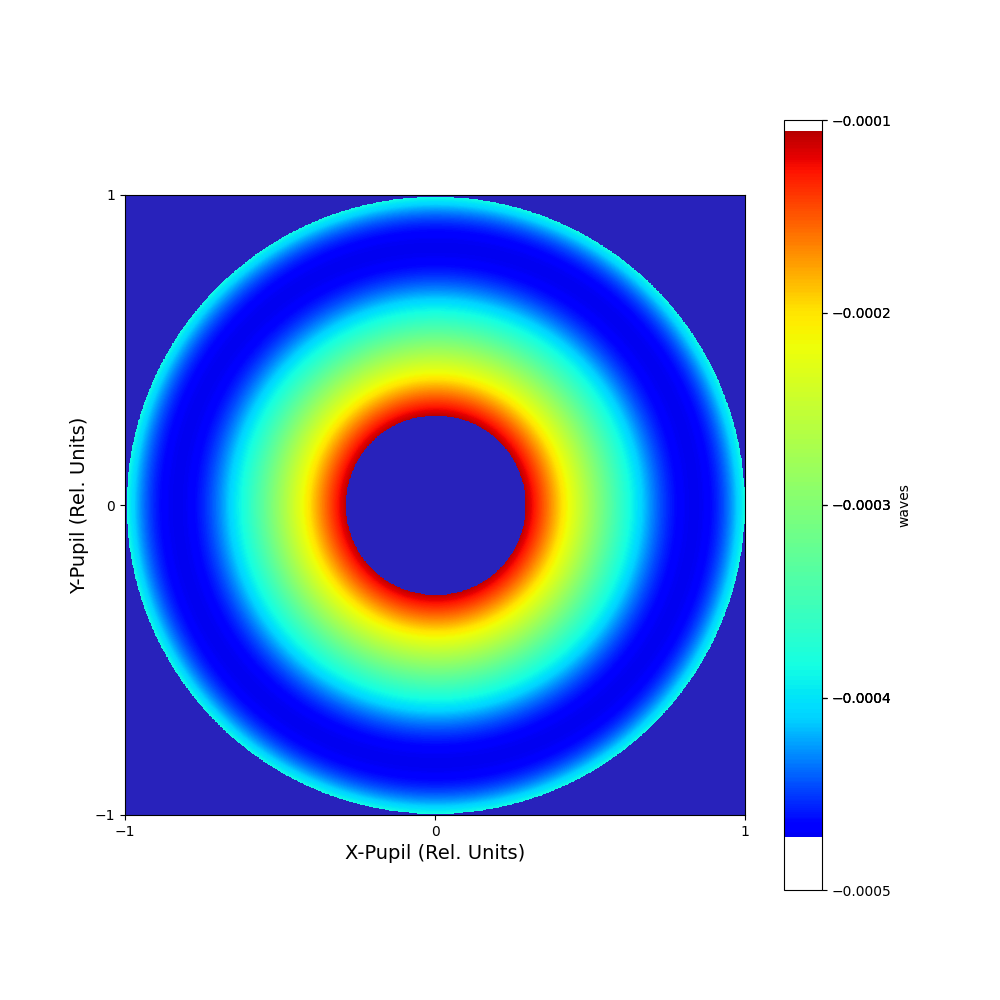

09/02/2025
0.65 µm at 0.0, 0.0 (deg)
Peak to valley = 0.0004 waves, RMS = 0.0001 waves
Zernikes :

RMS (to chief)    :    0.000174896 (waves)

Z   1     -0.000353890  :      1
Z   2     -0.000000000  :      4^(1/2) (P) * COS (A)
Z   3      0.000000000  :      4^(1/2) (P) * SIN (A)
Z   4     -0.000109988  :      3^(1/2) (2P^2-1)
Z   5      0.000000000  :      6^(1/2) (p^2) * SIN (2A)
Z   6     -0.000000000  :      6^(1/2) (p^2) * COS (2A)
Z   7      0.000000000  :      8^(1/2) (3p^3 - 2p) * SIN (A)
Z   8     -0.000000000  :      8^(1/2) (3p^3 - 2p) * COS (A)
Z   9      0.000000000  :      8^(1/2) (p^3) * SIN (3A)
Z  10     -0.000000000  :      8^(1/2) (p^3) * COS (3A)
Z  11      0.000073074  :      5^(1/2) (6p^4-6p^2+1)
Z  12     -0.000000000  :      10^(1/2) (4p^4-3p^2) * COS (2A)
Z  13      0.000000000  :      10^(1/2) (4p^4 - 3p^2) * SIN (2A)


2D and/or 3D calculation + plot time 1.09486 s
F/# in Image Space     : 44.50419
Paraxial Working F/#   : 44.50449
Working F/#            : 44.50419
NA in Image Space      : 0.0112349
Effective Focal Length : -17801.8 mm
XP position            : 920.201 mm
Airy radius            : 35.2823 µm
Out/In Flux            : 92.16 %
Strehl Ratio           : 1.0


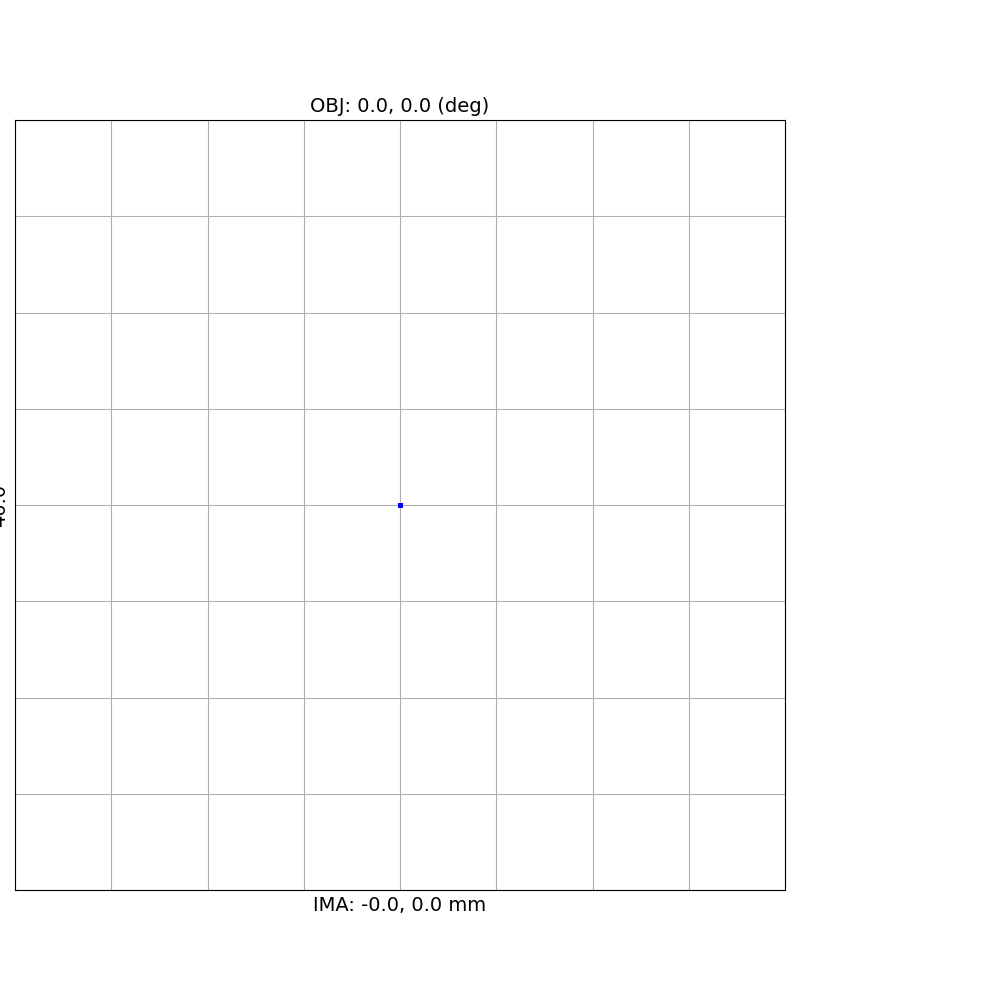

09/02/2025
Units are µm. Airy Radius: 35.282 µm. Wavelength: 0.65 µm.
RMS radius :    0.039
GEO radius :    0.07
Scale bar  :   40.0    Reference : Centroid



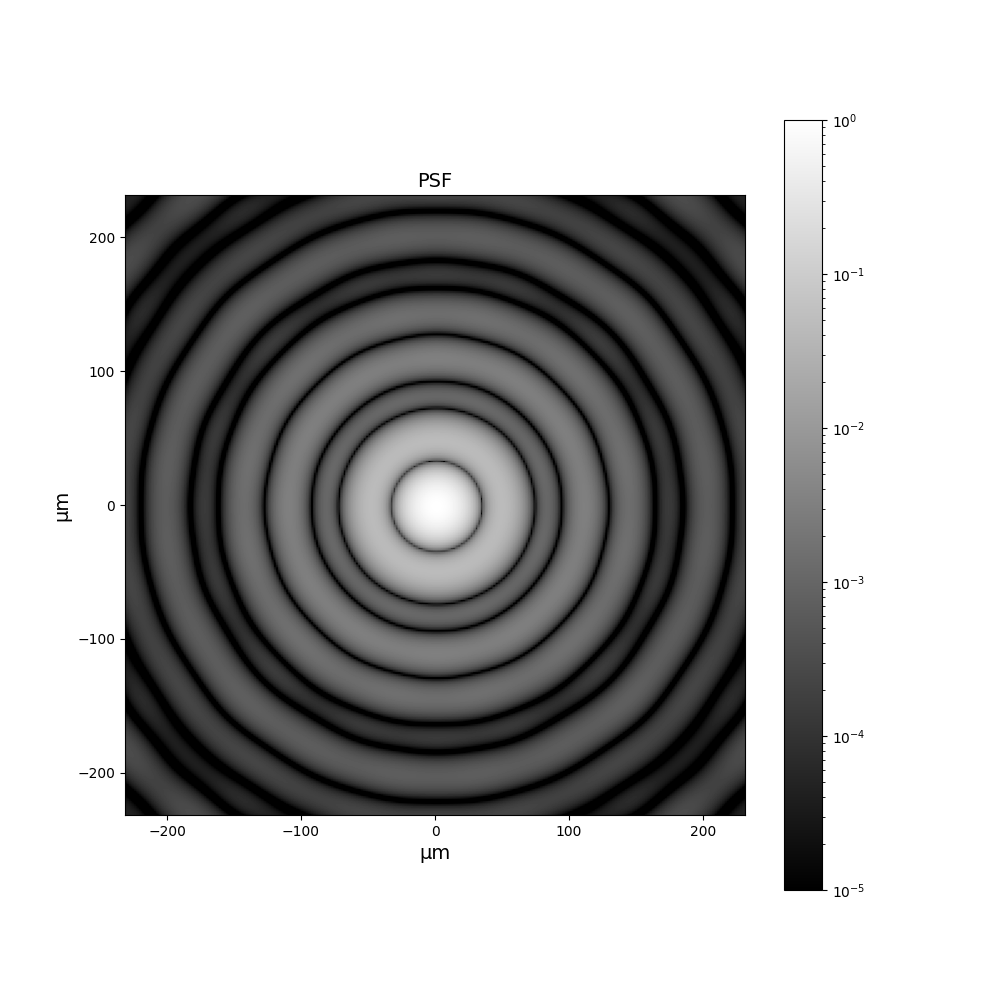


PSF calculation+plot time 0.98406


In [533]:
WL = 650e-9
def main():
    %run Batoid4LOFT.ipynb

    plt.close('all')

    global fieldBias
    fieldBias = 0.0 #Strehl ratio = 0.867

    telescopeCreation(WL, dxs=0, dys=0, dzs=0, txs=0.0, tys=0.00)

    ## Select what you want to see
    showWavefrontMap(WL)
    showLayout(show='2D')
    showSpotDiagram(WL, fieldX=0, fieldY=0)
    showPSF(WL)

if __name__=='__main__':
    main()

In [430]:
%run Batoid4LOFT.ipynb
telescope = telescopeCreation(650e-9, dxs=0.0, dys=0.00, dzs=-0.0, txs=0.0, tys=0.0)
infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=650e-9)
PSFNA, StehlRatioNA = infoTelescope.fftPSF(npx=128, pad=16)

In [534]:
infoTelescope = details(telescope)
WF = infoTelescope.wavefront(npx=1024, background=False)

In [535]:
e = poppy.zernike.decompose_opd(WF)

In [536]:
e

[-0.0003911323870674373,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan]

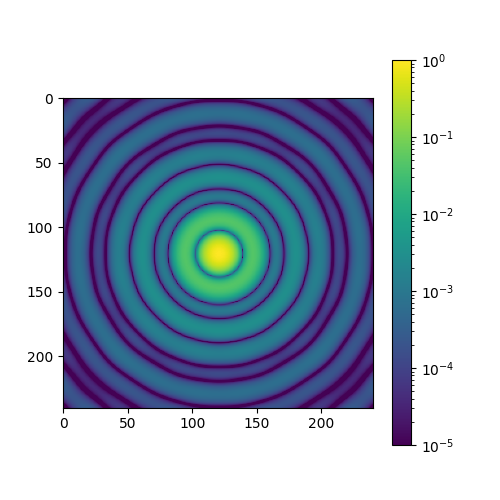

In [431]:
fig, ax = plt.subplots(figsize=(5,5))
WFax = ax.imshow(PSFNA[904:1144,904:1144], cmap='viridis', norm=mcolors.LogNorm(vmin=1e-5, vmax=1))
cbar = fig.colorbar(WFax)

In [432]:
def model(theta):
    dx, dy, dz, tx, ty = theta
    %run Batoid4LOFT.ipynb
    telescope = telescopeCreation(650e-9, dxs=dx, dys=dy, dzs=dz, txs=tx, tys=ty)
    infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=650e-9)
    PSF, StehlRatio = infoTelescope.fftPSF(npx=128, pad=16)
    return PSF

In [433]:
def lnlike(theta, y, yerr):
    return -0.5 * np.sum(((y - model(theta))/yerr) ** 2)

In [434]:
def lnprior(theta):
    dx, dy, dz, tx, ty = theta
    if -0.002 < dx < 0.002 and -0.006 < dy < 0.006 and -0.09 < dz < 0.09 and -0.7 < tx < 0.7 and -0.2 < ty < 0.2:
        return 0.0
    return -np.inf

In [435]:
def lnprob(theta, y, yerr):
    lp = lnprior(theta)
    if not np.isfinite(lp):
        return -np.inf
    return lp + lnlike(theta, y, yerr)

In [436]:
ierr = 0.05*np.mean(PSFNA)
data = (PSFNA, ierr)
nwalkers = 64
niter = 50
initial = np.array([0, 0, 0, 0, 0])
ndim = len(initial)
p0 = [np.array(initial) + 1e-7 * np.random.randn(ndim) for i in range(nwalkers)]

In [437]:
if __name__ == '__main__':
    with Pool(4) as pool:
        sampler = emcee.EnsembleSampler(nwalkers, ndim, lnprob, args=data, pool=pool)

        print("Running burn-in...")
        p0, _, _ = sampler.run_mcmc(p0, 5, progress=True)
        sampler.reset()
    
        print("Running production...")
        pos, prob, state = sampler.run_mcmc(p0, niter, progress=True)

Running burn-in...


100%|██████████| 5/5 [01:15<00:00, 15.14s/it]


Running production...


100%|██████████| 50/50 [12:21<00:00, 14.82s/it]


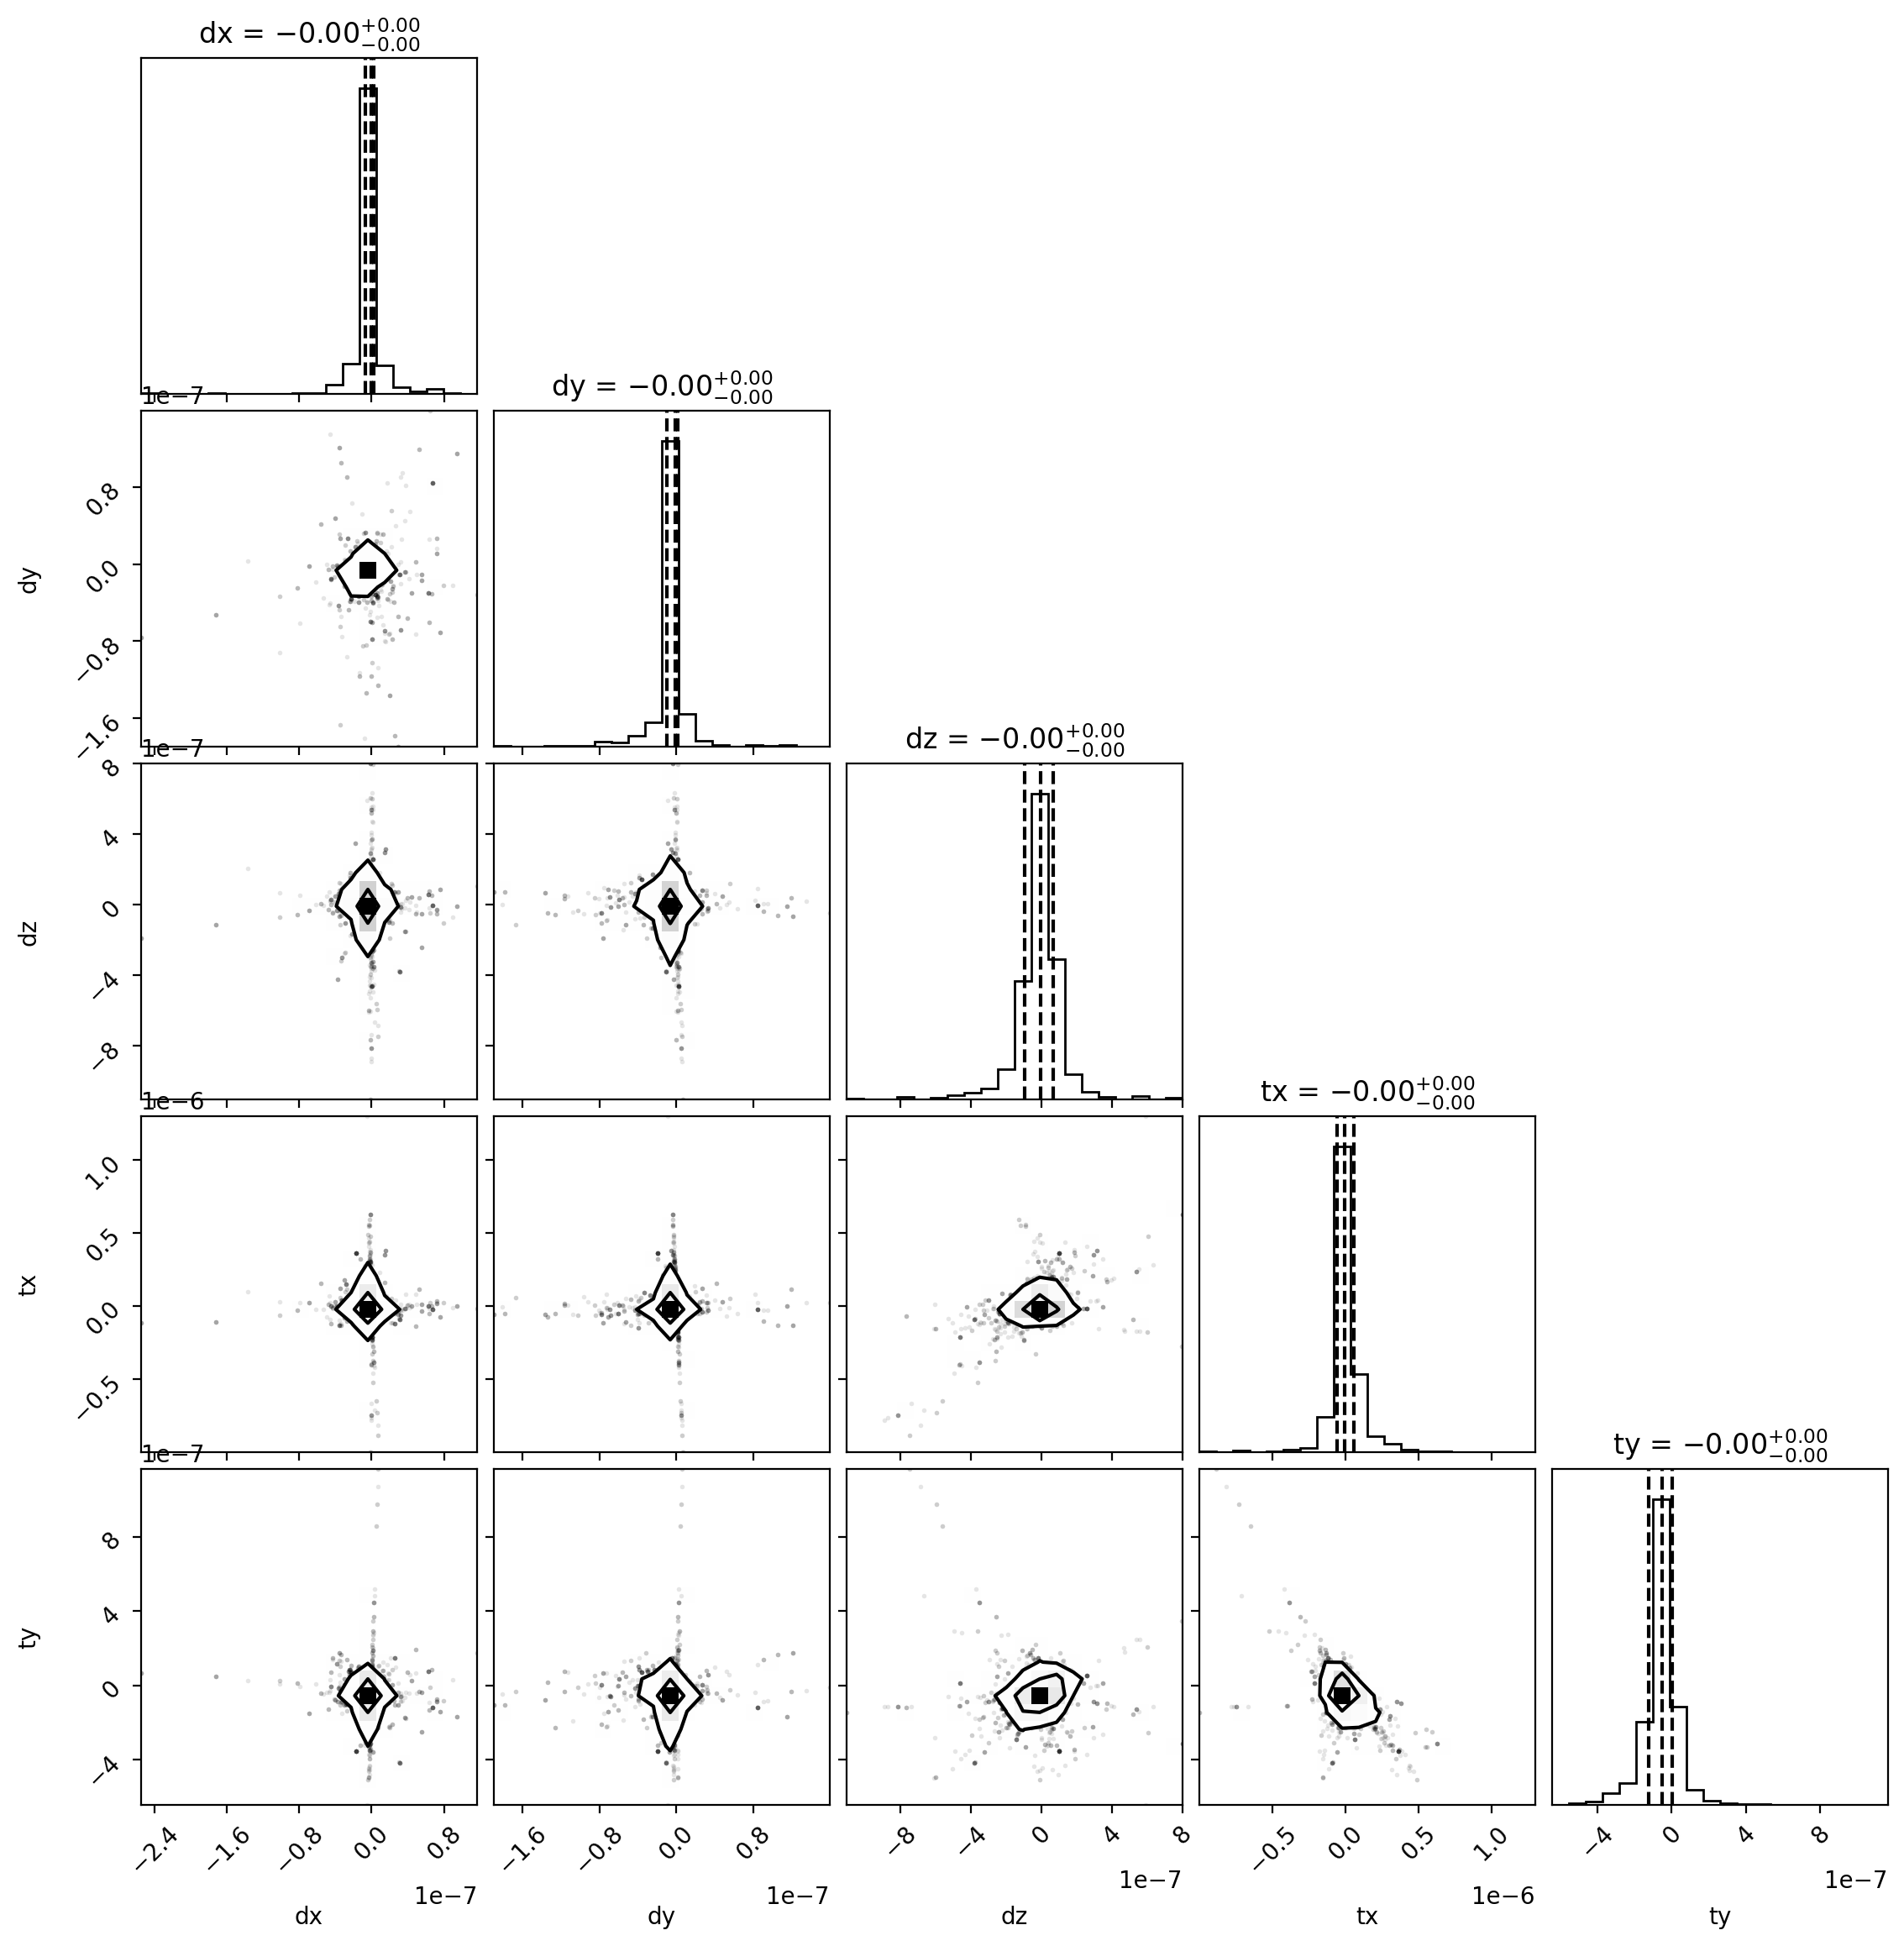

In [441]:
%matplotlib inline
samples = sampler.flatchain
labels = ['dx', 'dy', 'dz', 'tx', 'ty']
fig = corner.corner(samples,show_titles=True,labels=labels,plot_datapoints=True,quantiles=[0.16, 0.5, 0.84])

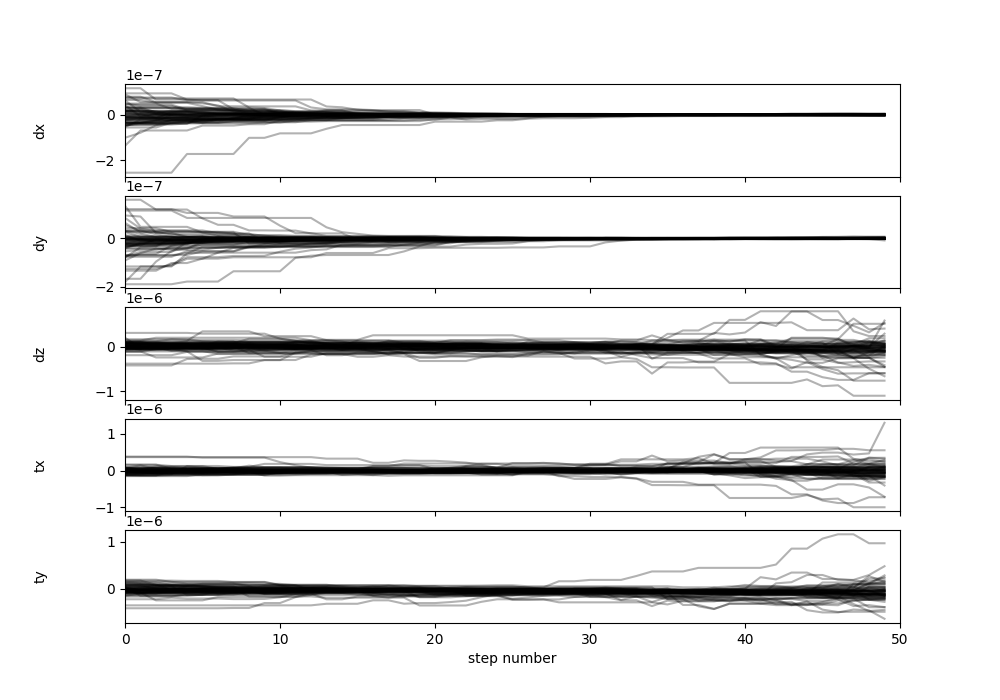

In [439]:
fig, axes = plt.subplots(5, figsize=(10, 7), sharex=True)
samples = sampler.get_chain()
labels = ["dx", "dy", "dz", "tx", "ty"]
for i in range(ndim):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number");

In [445]:
log_prob = sampler.get_log_prob()

In [481]:
log_prob.shape

(50, 64)

In [448]:
samples.shape

(3200, 5)

In [480]:
samples.shape

(3200, 5)

In [483]:
fsamples = np.reshape(samples, (50, 64, 5))

In [488]:
samples[1]

array([ 2.26437623e-08, -2.87669439e-08,  1.12237156e-07, -1.14742383e-07,
        8.25097142e-08])

In [491]:
fsamples[0].shape

(64, 5)

In [512]:
fsamples.shape

(50, 64, 5)

In [513]:
x = []
y = []
for i in range(50):
    chains = fsamples[i]
    lpc = log_prob[i] 
    for j in range(64):
        dx, dy, dz, tx, ty = chains[j]
        lp = lpc[j]
        %run Batoid4LOFT.ipynb
        telescope = telescopeCreation(650e-9, dxs=dx, dys=dy, dzs=dz, txs=tx, tys=ty)
        infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=650e-9)
        PSF, StehlRatio = infoTelescope.fftPSF(npx=128, pad=16)
        x.append(StehlRatio)
        y.append(lp)

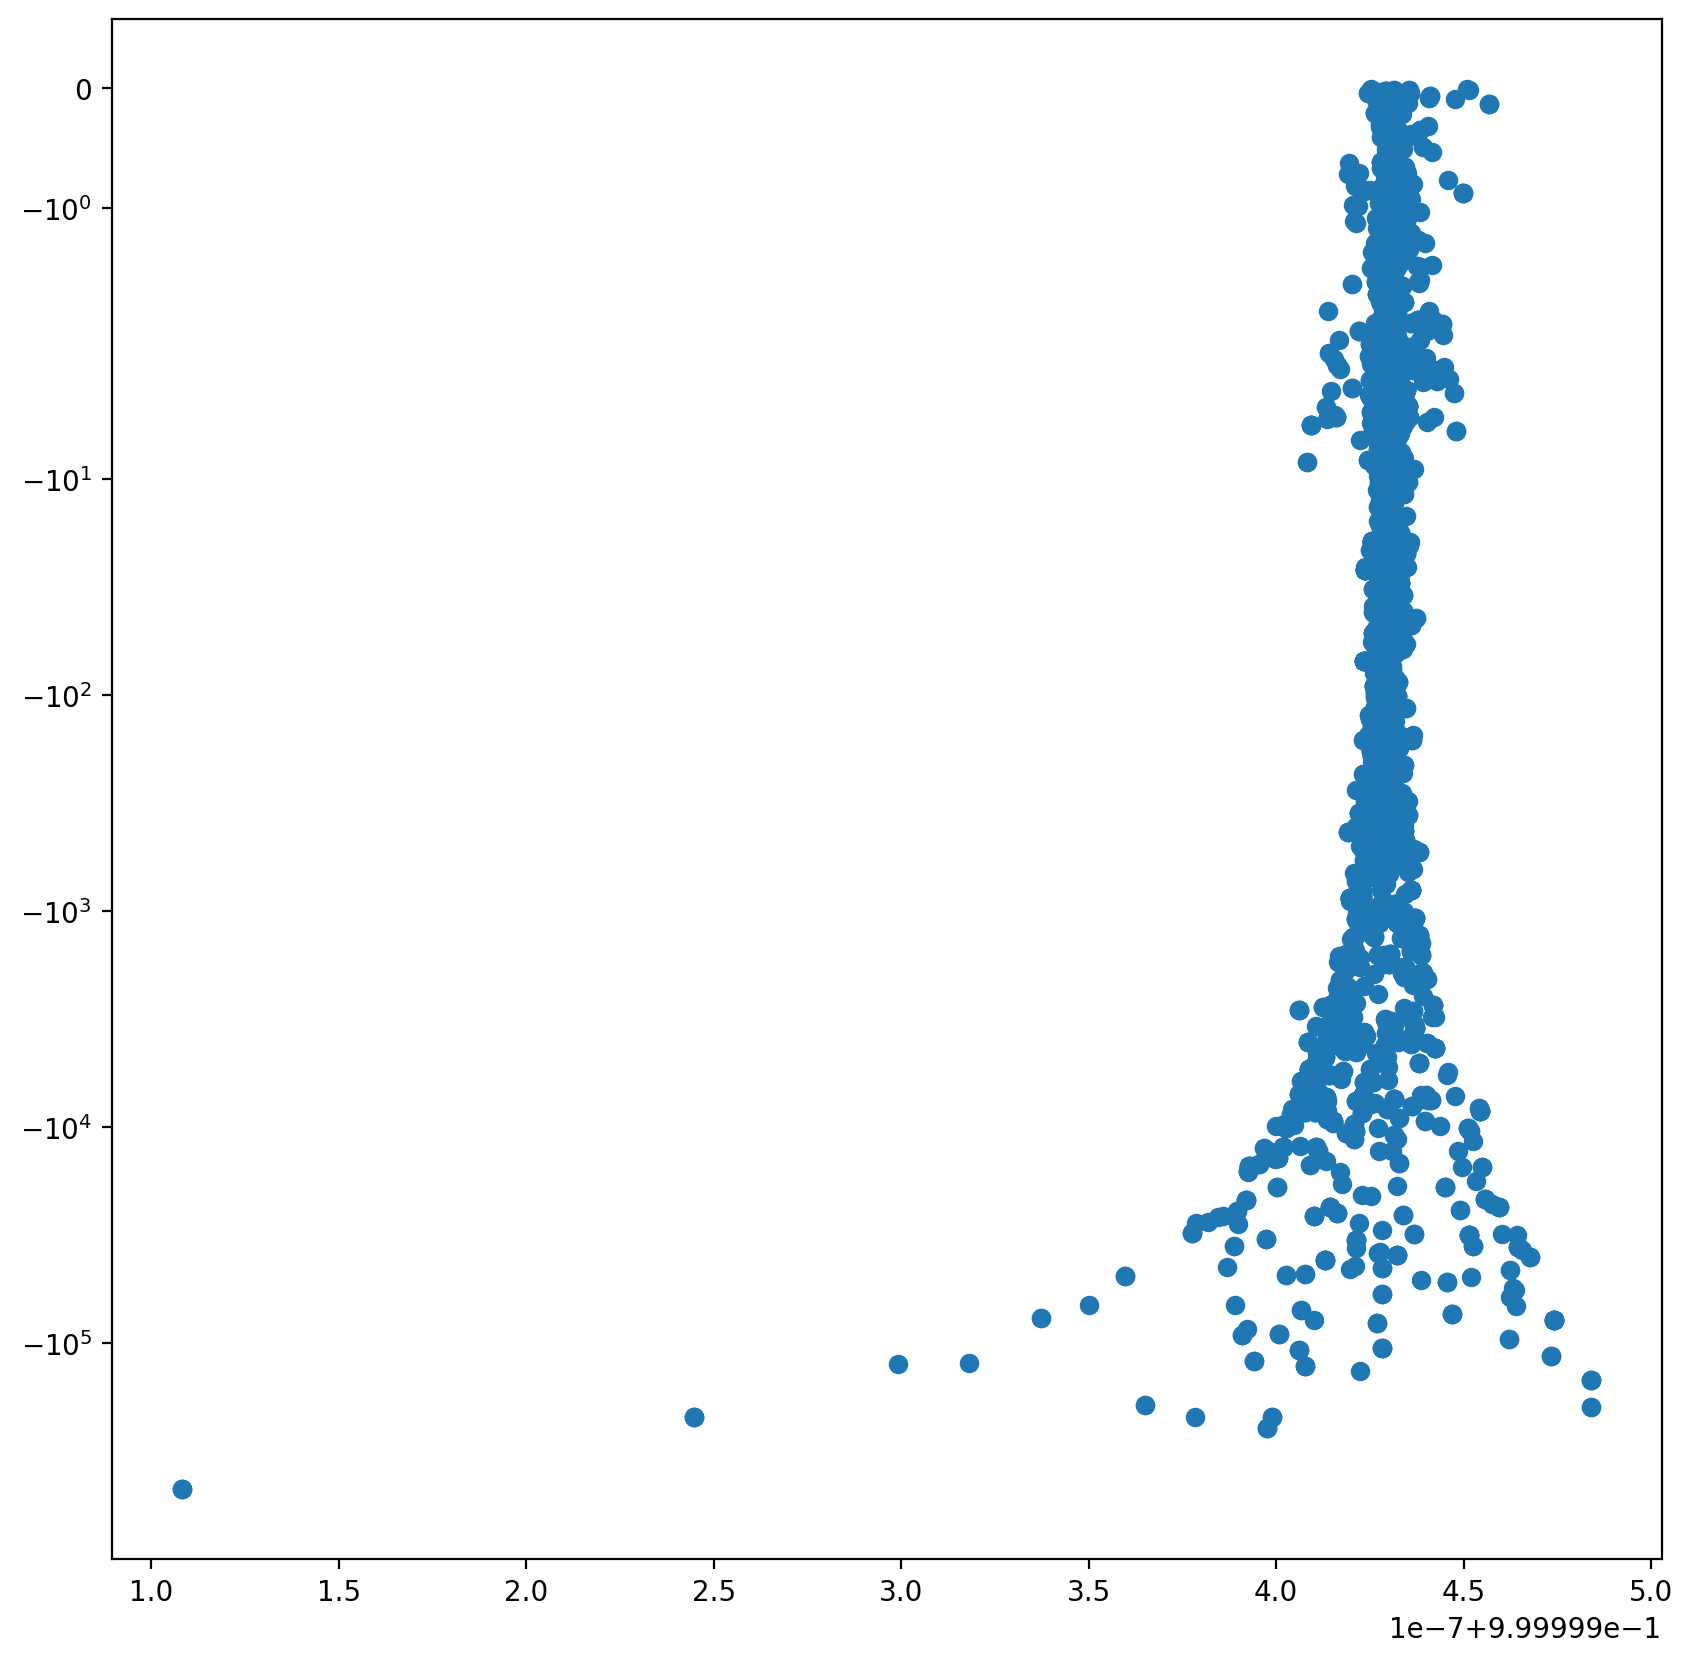

In [516]:
%matplotlib inline
plt.scatter(x,y)
plt.yscale('symlog')
plt.show()

In [ ]:
x = []
y = []
for i in range(3200):
    dx, dy, dz, tx, ty = samples[i]
    %run Batoid4LOFT.ipynb
    telescope = telescopeCreation(650e-9, dxs=dx, dys=dy, dzs=dz, txs=tx, tys=ty)
    infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=650e-9)
    PSF, StehlRatio = infoTelescope.fftPSF(npx=128, pad=16)
    LP = log_prob
    x.append(StehlRatio)
    y.append(LP)

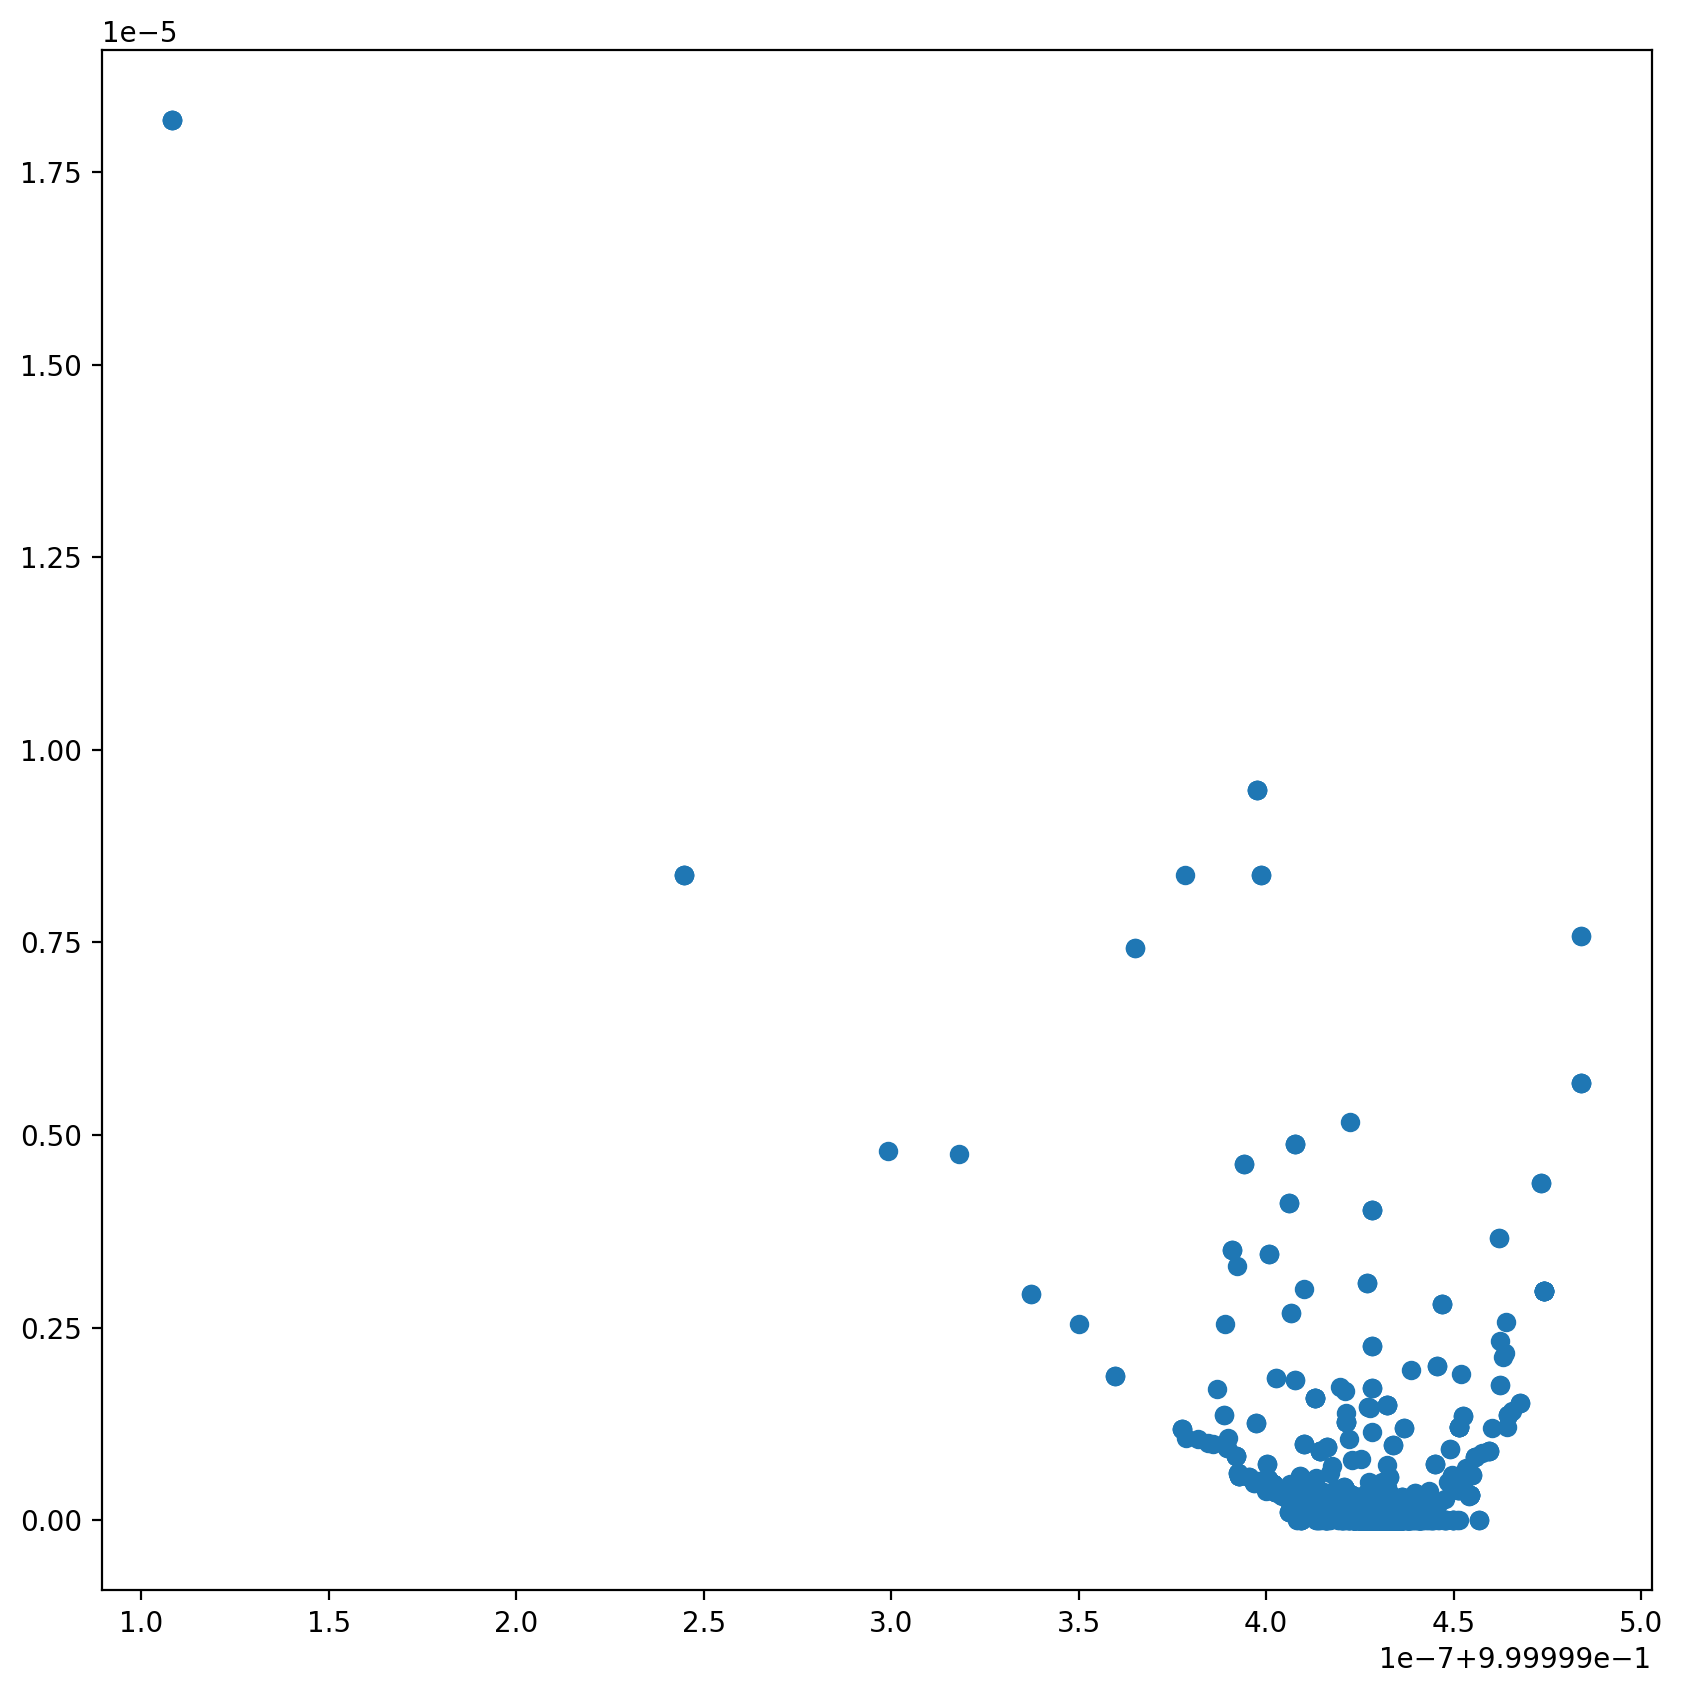

In [476]:
%matplotlib inline
plt.scatter(x,y)
plt.show()

In [ ]:
%run Batoid4LOFT.ipynb
telescope = telescopeCreation(650e-9, dxs=0.0, dys=0.00, dzs=-0.0, txs=0.0, tys=0.0)
infoTelescope = details(telescope, fieldX=0, fieldY=0, wavelength=650e-9)
PSFNA, StehlRatioNA = infoTelescope.fftPSF(npx=128, pad=16)